# Etapa 6 — Análisis de errores

## Objetivo

Identificar en qué situaciones falla la candidata seleccionada:
verde con corrección del fondo, detector de líneas, resolución
de trabajo 1/4 y Otsu, sin limpieza.

Se utilizan únicamente las imágenes de desarrollo.
En esta etapa se analiza el resultado sin modificar el método.

## Detección según el grosor

Se mide qué proporción de la línea central de los vasos del
experto queda incluida en la máscara predicha, separando vasos
finos, medianos y gruesos con los límites fijados en la etapa 1.

In [2]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path
import os
import sys

ROOT = Path("/content/drive/MyDrive/TP-PSI-G8-karo_03")

assert (ROOT / "src" / "segment.py").exists(), (
    "No encontramos el proyecto. Revisá el nombre de la carpeta en ROOT."
)

os.chdir(ROOT)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Ubicación correcta:", ROOT)

Ubicación correcta: /content/drive/MyDrive/TP-PSI-G8-karo_03


In [4]:
import numpy as np
import pandas as pd

from src.config import RESULTS_DIR, WIDTH_LIMITS_PX
from src.data import dev_ids, load_image, load_vessels, load_fov
from src.enhance import upscale
from src.fov import detect_fov_robust
from src.segment import segmentar_otsu
from src.metrics import (
    matthews,
    dice,
    centerline_dice,
    centerline_sensitivity_by_class,
)

carpeta_mapas = (
    RESULTS_DIR / "05_logistica_pc3_verde_textura_v1"
)

filas = []
ids = dev_ids()

for numero, imagen_id in enumerate(ids, start=1):
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id)
    campo_auto = detect_fov_robust(load_image(imagen_id))

    with np.load(carpeta_mapas / f"{imagen_id}.npz") as datos:
        verde = datos["entradas"][:, :, 1]

    puntuacion = upscale(verde, referencia.shape)
    mascara, _ = segmentar_otsu(puntuacion, campo_auto)

    sensibilidad = centerline_sensitivity_by_class(
        mascara, referencia, WIDTH_LIMITS_PX, region=campo_ref
    )

    filas.append({
        "Imagen": imagen_id,
        "Matthews": matthews(mascara, referencia, campo_ref),
        "Dice": dice(mascara, referencia, campo_ref),
        "Dice línea central": centerline_dice(
            mascara, referencia, campo_ref
        ),
        "Sensibilidad finos": sensibilidad["fino"],
        "Sensibilidad medianos": sensibilidad["mediano"],
        "Sensibilidad gruesos": sensibilidad["grueso"],
    })

    print(f"{numero}/{len(ids)} terminada: {imagen_id}", flush=True)

tabla_errores = pd.DataFrame(filas)
tabla_errores.to_csv(
    RESULTS_DIR / "06_errores_por_grosor.csv", index=False
)

columnas = [
    "Sensibilidad finos",
    "Sensibilidad medianos",
    "Sensibilidad gruesos",
]

display(
    tabla_errores[columnas]
    .mean()
    .rename("Sensibilidad media")
    .to_frame()
    .round(4)
)

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Sensibilidad media
Sensibilidad finos,0.1074
Sensibilidad medianos,0.5879
Sensibilidad gruesos,0.9165


### Resultado por grosor

La sensibilidad media sobre la línea central fue de 0,1074
para vasos finos, 0,5879 para medianos y 0,9165 para gruesos.

La principal limitación de la candidata es la detección de vasos
finos. El rendimiento global debe interpretarse junto con esta
diferencia por grosor.

Este análisis no permite atribuir la pérdida a una etapa concreta:
pueden influir la reducción de resolución, el realce y el umbral.

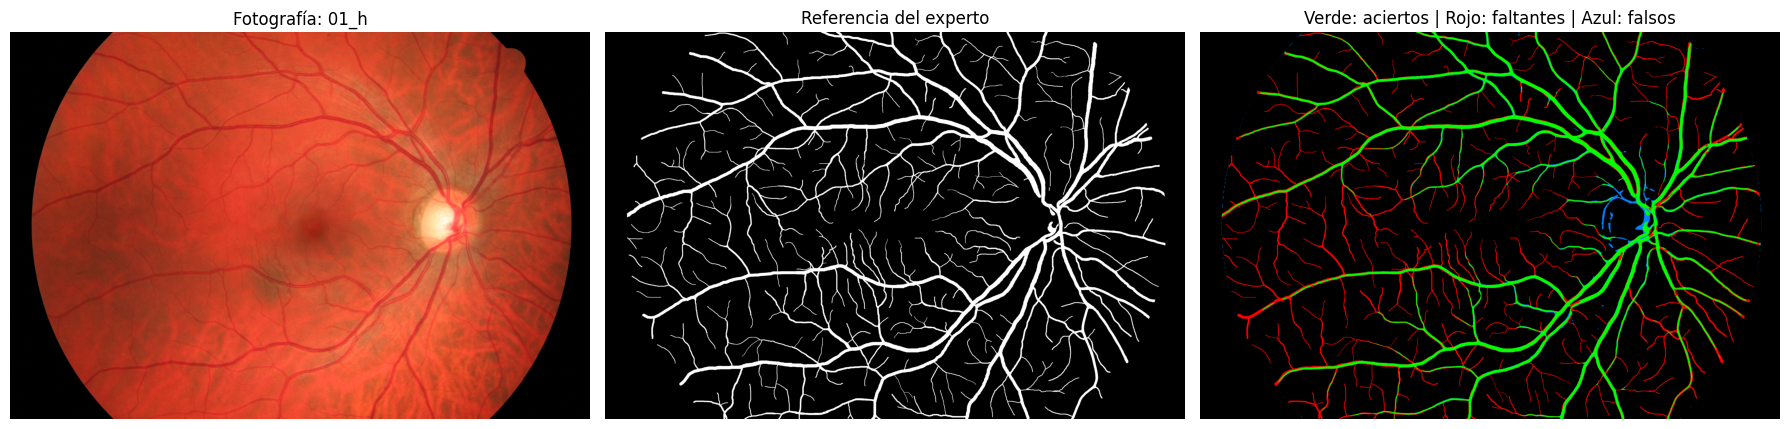

In [5]:
import matplotlib.pyplot as plt

imagen_id = "01_h"

foto = load_image(imagen_id)
referencia = load_vessels(imagen_id).astype(bool)
campo_ref = load_fov(imagen_id).astype(bool)
campo_auto = detect_fov_robust(foto)

with np.load(carpeta_mapas / f"{imagen_id}.npz") as datos:
    verde = datos["entradas"][:, :, 1]

puntuacion = upscale(verde, referencia.shape)
mascara, _ = segmentar_otsu(puntuacion, campo_auto)

aciertos = mascara & referencia & campo_ref
faltantes = ~mascara & referencia & campo_ref
falsos = mascara & ~referencia & campo_ref

errores = np.zeros((*referencia.shape, 3), dtype=np.uint8)
errores[aciertos] = [0, 255, 0]
errores[faltantes] = [255, 0, 0]
errores[falsos] = [0, 130, 255]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(foto)
axes[0].set_title(f"Fotografía: {imagen_id}")

axes[1].imshow(referencia, cmap="gray")
axes[1].set_title("Referencia del experto")

axes[2].imshow(errores)
axes[2].set_title("Verde: aciertos | Rojo: faltantes | Azul: falsos")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

### Inspección visual: 01_h

La predicción recupera gran parte de los vasos principales,
pero omite numerosas ramas finas. También aparecen falsas
detecciones cerca del disco óptico.

El ejemplo es consistente con la sensibilidad medida por grosor:
alta en vasos gruesos y baja en finos. Esta imagen ilustra el
problema; los resultados de las 30 imágenes sostienen la conclusión.

In [7]:
from src.data import load_split

# Recuperamos las métricas guardadas por si se reinició la sesión.
tabla_errores = pd.read_csv(
    RESULTS_DIR / "06_errores_por_grosor.csv"
)

metadatos = load_split()[
    ["image", "group", "person", "more_compressed"]
]

analisis = tabla_errores.merge(
    metadatos,
    left_on="Imagen",
    right_on="image",
    validate="one_to_one",
)

analisis["Grupo"] = analisis["group"].map({
    "h": "Sanos",
    "dr": "Retinopatía diabética",
    "g": "Glaucoma",
})

# Funciona tanto si la columna se leyó como booleano o como texto.
analisis["Compresión"] = (
    analisis["more_compressed"]
    .astype(str).str.lower()
    .map({"true": "Mayor", "false": "Menor"})
)

assert analisis[["Grupo", "Compresión"]].notna().all().all()

def resumir_grupos(columnas):
    return analisis.groupby(columnas).agg(
        Imagenes=("Imagen", "count"),
        Matthews=("Matthews", "mean"),
        Dice_linea_central=("Dice línea central", "mean"),
        Sensibilidad_finos=("Sensibilidad finos", "mean"),
    ).round(4)

print("Por grupo clínico:")
display(resumir_grupos(["Grupo"]))

print("Por compresión:")
display(resumir_grupos(["Compresión"]))

print("Grupo clínico dentro de cada nivel de compresión:")
display(resumir_grupos(["Compresión", "Grupo"]))

analisis.to_csv(
    RESULTS_DIR / "06_errores_con_metadatos.csv",
    index=False,
)

Por grupo clínico:


,Imagenes,Matthews,Dice_linea_central,Sensibilidad_finos
Grupo,,,,
Glaucoma,10,0.6846,0.6215,0.0889
Retinopatía diabética,10,0.6410,0.6122,0.1637
Sanos,10,0.7042,0.6683,0.0696


Por compresión:


,Imagenes,Matthews,Dice_linea_central,Sensibilidad_finos
Compresión,,,,
Mayor,12,0.6821,0.6377,0.0964
Menor,18,0.6730,0.6316,0.1148


Grupo clínico dentro de cada nivel de compresión:


Imagenes  Matthews  Dice_linea_central  \
Compresión Grupo                                                           
Mayor      Glaucoma                      4    0.6748              0.6346   
           Retinopatía diabética         2    0.6219              0.5655   
           Sanos                         6    0.7071              0.6638   
Menor      Glaucoma                      6    0.6912              0.6128   
           Retinopatía diabética         8    0.6458              0.6238   
           Sanos                         4    0.6999              0.6752   

                                  Sensibilidad_finos  
Compresión Grupo                                      
Mayor      Glaucoma                           0.1050  
           Retinopatía diabética              0.1085  
           Sanos                              0.0866  
Menor      Glaucoma                           0.0782  
           Retinopatía diabética              0.1776  
           Sanos                              0.0441

### Resultados por grupo clínico y compresión

El grupo con retinopatía presentó el menor Matthews medio
(0,6410), seguido de glaucoma (0,6846) y sanos (0,7042).
El Dice de línea central mantuvo el mismo orden.

La sensibilidad en vasos finos fue baja en todos los grupos.
Aunque retinopatía presentó la mayor sensibilidad en finos,
esto no implica un mejor resultado global.

No se observó un deterioro global claro asociado a mayor
compresión en estas imágenes. La distribución de compresión
fue diferente entre grupos y algunas categorías tuvieron
pocas imágenes.

Estas comparaciones son descriptivas: no permiten atribuir
las diferencias a la enfermedad o a la compresión ni justifican,
por sí solas, modificar el algoritmo.

## Errores por zona

Se aproxima el centro del disco óptico mediante el máximo de
brillo de la fotografía suavizada dentro del campo automático.

Se define una zona circular con radio de 0,10 veces el diámetro
del campo. Este radio es una decisión exploratoria, no una
medida anatómica validada.

Se compara Matthews cerca de ese centro y en el resto del campo,
sin modificar la segmentación.

1/30 terminada: 01_h
2/30 terminada: 02_h
3/30 terminada: 03_h
4/30 terminada: 04_h
5/30 terminada: 07_h
6/30 terminada: 08_h
7/30 terminada: 09_h
8/30 terminada: 10_h
9/30 terminada: 13_h
10/30 terminada: 14_h
11/30 terminada: 03_dr
12/30 terminada: 04_dr
13/30 terminada: 05_dr
14/30 terminada: 06_dr
15/30 terminada: 08_dr
16/30 terminada: 10_dr
17/30 terminada: 11_dr
18/30 terminada: 12_dr
19/30 terminada: 13_dr
20/30 terminada: 14_dr
21/30 terminada: 03_g
22/30 terminada: 04_g
23/30 terminada: 05_g
24/30 terminada: 06_g
25/30 terminada: 07_g
26/30 terminada: 08_g
27/30 terminada: 11_g
28/30 terminada: 12_g
29/30 terminada: 13_g
30/30 terminada: 14_g


,Matthews,Dice
Zona,,
Cerca del disco estimado,0.6782,0.7369
Resto del campo,0.6756,0.6918


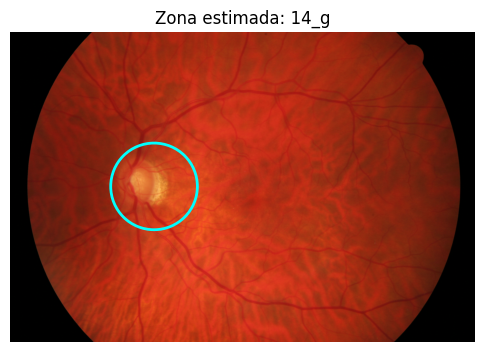

In [8]:
from scipy.ndimage import gaussian_filter
from src.fov import fov_diameter

filas_zonas = []

for numero, imagen_id in enumerate(ids, start=1):
    foto = load_image(imagen_id)
    referencia = load_vessels(imagen_id)
    campo_ref = load_fov(imagen_id).astype(bool)
    campo_auto = detect_fov_robust(foto)
    diametro = fov_diameter(campo_auto)

    with np.load(carpeta_mapas / f"{imagen_id}.npz") as datos:
        verde = datos["entradas"][:, :, 1]

    puntuacion = upscale(verde, referencia.shape)
    mascara, _ = segmentar_otsu(puntuacion, campo_auto)

    # Localización aproximada del disco, usando solo la fotografía.
    brillo = foto.astype(np.float32).mean(axis=2)
    suave = gaussian_filter(brillo, sigma=0.02 * diametro)
    suave[~campo_auto] = -np.inf

    cy, cx = np.unravel_index(np.argmax(suave), suave.shape)

    yy, xx = np.ogrid[:referencia.shape[0], :referencia.shape[1]]
    cerca = (yy - cy)**2 + (xx - cx)**2 <= (0.10 * diametro)**2

    for nombre, region in {
        "Cerca del disco estimado": campo_ref & cerca,
        "Resto del campo": campo_ref & ~cerca,
    }.items():
        filas_zonas.append({
            "Imagen": imagen_id,
            "Zona": nombre,
            "Centro x": cx,
            "Centro y": cy,
            "Matthews": matthews(mascara, referencia, region),
            "Dice": dice(mascara, referencia, region),
        })

    print(f"{numero}/{len(ids)} terminada: {imagen_id}", flush=True)

tabla_zonas = pd.DataFrame(filas_zonas)
tabla_zonas.to_csv(
    RESULTS_DIR / "06_errores_por_zona.csv", index=False
)

display(
    tabla_zonas.groupby("Zona")[["Matthews", "Dice"]]
    .mean()
    .round(4)
)

# Control visual de la ubicación estimada en la última imagen.
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(foto)
ax.add_patch(
    plt.Circle(
        (cx, cy), 0.10 * diametro,
        fill=False, color="cyan", linewidth=2
    )
)
ax.set_title(f"Zona estimada: {imagen_id}")
ax.axis("off")
plt.show()

### Resultado por zona

Matthews medio fue de 0,6782 cerca del disco estimado y de
0,6756 en el resto del campo. Dice fue de 0,7369 y 0,6918,
respectivamente.

No se observó un menor rendimiento medio cerca del disco.
Esto no implica ausencia de falsas detecciones en esa zona.

La ubicación del disco es aproximada. El control visual mostrado
para 14_g fue adecuado, pero no valida todas las localizaciones.

In [9]:
from src.config import SEED

analisis = pd.read_csv(
    RESULTS_DIR / "06_errores_con_metadatos.csv"
)

metricas = ["Matthews", "Dice línea central"]
valores = analisis[metricas].to_numpy(dtype=float)

assert np.isfinite(valores).all(), "Hay métricas faltantes."

personas = analisis["person"].unique()
indice_persona = pd.Categorical(
    analisis["person"], categories=personas
).codes

# Cada fila contiene cuántas veces se sorteó cada persona.
rng = np.random.default_rng(SEED)
remuestreos = np.array([
    np.bincount(
        rng.integers(0, len(personas), size=len(personas)),
        minlength=len(personas),
    )
    for _ in range(2000)
])

comparaciones = [
    ("Grupo", "Sanos"),
    ("Grupo", "Retinopatía diabética"),
    ("Grupo", "Glaucoma"),
    ("Compresión", "Mayor"),
]

filas_intervalos = []

for columna, grupo in comparaciones:
    pertenece = analisis[columna].eq(grupo).to_numpy()
    resto = ~pertenece

    diferencia = (
        valores[pertenece].mean(axis=0)
        - valores[resto].mean(axis=0)
    )

    diferencias_boot = []

    for conteos in remuestreos:
        pesos = conteos[indice_persona]

        if pesos[pertenece].sum() == 0 or pesos[resto].sum() == 0:
            continue

        media_grupo = np.average(
            valores[pertenece], axis=0,
            weights=pesos[pertenece],
        )
        media_resto = np.average(
            valores[resto], axis=0,
            weights=pesos[resto],
        )
        diferencias_boot.append(media_grupo - media_resto)

    inferior, superior = np.percentile(
        diferencias_boot, [2.5, 97.5], axis=0
    )

    for j, metrica in enumerate(metricas):
        filas_intervalos.append({
            "Comparación": f"{grupo} frente al resto",
            "Métrica": metrica,
            "Diferencia": diferencia[j],
            "Límite inferior 95%": inferior[j],
            "Límite superior 95%": superior[j],
            "Peor con intervalo bajo cero": superior[j] < 0,
        })

tabla_intervalos = pd.DataFrame(filas_intervalos)

tabla_intervalos.to_csv(
    RESULTS_DIR / "06_intervalos_subgrupos.csv", index=False
)

display(tabla_intervalos.round(4))

,Comparación,Métrica,Diferencia,Límite inferior 95%,Límite superior 95%,Peor con intervalo bajo cero
0,Sanos frente al resto,Matthews,0.0414,0.0159,0.0727,False
1,Sanos frente al resto,Dice línea central,0.0515,0.0046,0.0868,False
2,Retinopatía diabética frente al resto,Matthews,-0.0534,-0.0836,-0.0253,True
3,Retinopatía diabética frente al resto,Dice línea central,-0.0328,-0.0727,0.0045,False
4,Glaucoma frente al resto,Matthews,0.0120,-0.0202,0.0450,False
5,Glaucoma frente al resto,Dice línea central,-0.0187,-0.0466,0.0137,False
6,Mayor frente al resto,Matthews,0.0092,-0.0275,0.0489,False
7,Mayor frente al resto,Dice línea central,0.0061,-0.0386,0.0529,False


## Conclusión y decisión

La principal limitación es la detección de vasos finos:
sensibilidad media de 0,1074, frente a 0,5879 en medianos
y 0,9165 en gruesos.

Retinopatía presentó menor Matthews que el resto:
diferencia de −0,0534, con IC95% [−0,0836; −0,0253].
Sin embargo, la diferencia en Dice de línea central tuvo
un intervalo que incluyó cero: [−0,0727; 0,0045].

Por lo tanto, no se activa la corrección dirigida prevista
en el plan, que requiere un deterioro confirmado en ambas
métricas. No se atribuye la diferencia a una causa específica.

No se encontraron diferencias claras por compresión.
Tampoco se observó menor Matthews medio cerca del disco
óptico estimado.

Se conserva la candidata sin modificaciones. La pérdida de
vasos finos queda documentada como una limitación importante.
Los resultados corresponden únicamente a desarrollo.